PART A: CORRELATED OUTCOMES
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

PART B: OPPOSITE OUTCOMES
     ┌───┐     ┌───┐┌─┐
q_0: ┤ H ├──■──┤ X ├┤M├
     └───┘┌─┴─┐└┬─┬┘└╥┘
q_1: ─────┤ X ├─┤M├──╫─
          └───┘ └╥┘  ║ 
c: 2/════════════╩═══╩═
                 1   0 

PREDICTIONS
Part A: Outcomes 00 and 11 should dominate.
Part B: Outcomes 01 and 10 should dominate.
Each expected outcome has a theoretical probability of 50%.

PART A MEASUREMENT COUNTS
{'11': 52, '00': 48}
Total shots: 100

PART B MEASUREMENT COUNTS
{'01': 39, '10': 61}
Total shots: 100


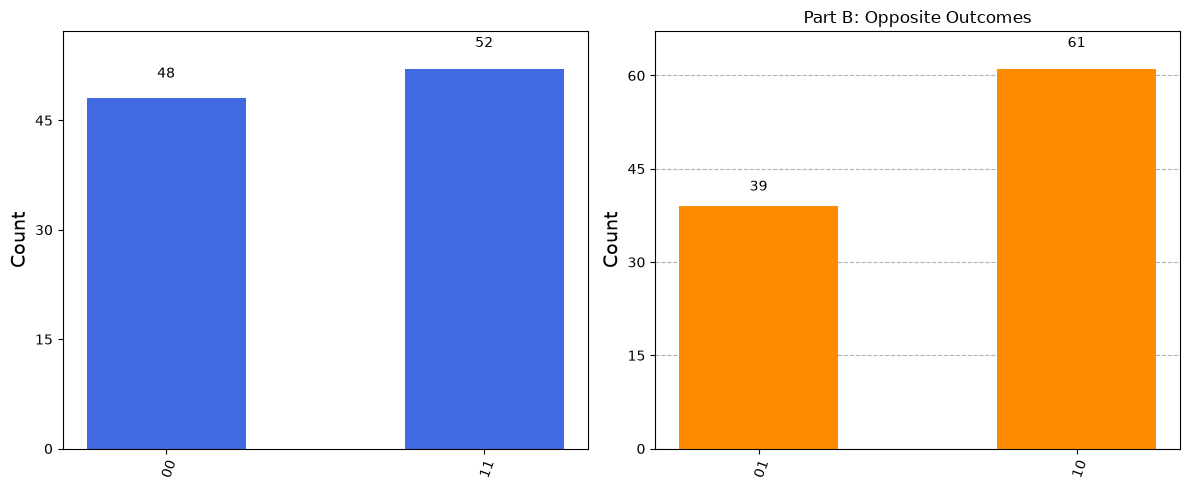


COMPARISON OF BOTH EXPERIMENTS
Outcome     Part A         Part B         
00          48             0              
01          0              39             
10          0              61             
11          52             0              

FINAL EXPLANATION

Part A:
The Hadamard gate and CNOT gate create a Bell state.
The dominant outcomes are 00 and 11, each with
a theoretical probability of 50%.

Part B:
An additional X gate is applied to qubit 0.
The dominant outcomes change to 01 and 10, each
with a theoretical probability of 50%.

Comparison:
The X gate flips one qubit and changes the
measurement relationship from correlated to opposite.
The qubits remain entangled. Outcomes 00 and 11
should be absent in the ideal Part B circuit, while
01 and 10 should be absent in the ideal Part A circuit.

Small variations in counts may occur in real quantum
hardware due to noise. In this simulator, differences
between the two expected counts are due to sampling.

Experiment completed su

In [1]:

# ============================================================
# CHALLENGE 4: QUANTUM CORRELATION SWITCH
# Complete Assignment Using Qiskit
# ============================================================

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize simulator
simulator = AerSimulator()
SHOTS = 100

# ============================================================
# PART A: CORRELATED OUTCOMES (00 and 11)
# ============================================================

circuit_A = QuantumCircuit(2, 2)

# Create a superposition
circuit_A.h(0)

# Entangle the two qubits
circuit_A.cx(0, 1)

# Measure both qubits
circuit_A.measure([0, 1], [0, 1])

print("=" * 55)
print("PART A: CORRELATED OUTCOMES")
print("=" * 55)
print(circuit_A.draw())

# ============================================================
# PART B: OPPOSITE OUTCOMES (01 and 10)
# ============================================================

circuit_B = QuantumCircuit(2, 2)

# Create the original Bell state
circuit_B.h(0)
circuit_B.cx(0, 1)

# Add one X gate to switch the correlation
circuit_B.x(0)

# Measure both qubits
circuit_B.measure([0, 1], [0, 1])

print("\n" + "=" * 55)
print("PART B: OPPOSITE OUTCOMES")
print("=" * 55)
print(circuit_B.draw())

# ============================================================
# PREDICTIONS BEFORE EXECUTION
# ============================================================

print("\nPREDICTIONS")
print("Part A: Outcomes 00 and 11 should dominate.")
print("Part B: Outcomes 01 and 10 should dominate.")
print("Each expected outcome has a theoretical probability of 50%.")

# ============================================================
# EXECUTE BOTH CIRCUITS FOR 100 SHOTS
# ============================================================

result_A = simulator.run(
    circuit_A, shots=SHOTS
).result()

result_B = simulator.run(
    circuit_B, shots=SHOTS
).result()

counts_A = result_A.get_counts()
counts_B = result_B.get_counts()

# ============================================================
# DISPLAY MEASUREMENT RESULTS
# ============================================================

print("\nPART A MEASUREMENT COUNTS")
print(counts_A)
print("Total shots:", sum(counts_A.values()))

print("\nPART B MEASUREMENT COUNTS")
print(counts_B)
print("Total shots:", sum(counts_B.values()))

# ============================================================
# PART C: HISTOGRAM COMPARISON
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_histogram(
    counts_A,
    ax=axes[0],
    title="Part A: Correlated Outcomes",
    color=["royalblue"]
)

plot_histogram(
    counts_B,
    ax=axes[1],
    title="Part B: Opposite Outcomes",
    color=["darkorange"]
)

plt.tight_layout()
plt.show()

# ============================================================
# COMPARISON TABLE
# ============================================================

print("\n" + "=" * 55)
print("COMPARISON OF BOTH EXPERIMENTS")
print("=" * 55)

print(f"{'Outcome':<12}{'Part A':<15}{'Part B':<15}")

for outcome in ["00", "01", "10", "11"]:
    a = counts_A.get(outcome, 0)
    b = counts_B.get(outcome, 0)
    print(f"{outcome:<12}{a:<15}{b:<15}")

# ============================================================
# FINAL EXPLANATION
# ============================================================

print("\nFINAL EXPLANATION")

print("""
Part A:
The Hadamard gate and CNOT gate create a Bell state.
The dominant outcomes are 00 and 11, each with
a theoretical probability of 50%.

Part B:
An additional X gate is applied to qubit 0.
The dominant outcomes change to 01 and 10, each
with a theoretical probability of 50%.

Comparison:
The X gate flips one qubit and changes the
measurement relationship from correlated to opposite.
The qubits remain entangled. Outcomes 00 and 11
should be absent in the ideal Part B circuit, while
01 and 10 should be absent in the ideal Part A circuit.

Small variations in counts may occur in real quantum
hardware due to noise. In this simulator, differences
between the two expected counts are due to sampling.
""")

print("Experiment completed successfully!")
